In [1]:
import sys

sys.path.append("..")

import numpy as np
from classes.sample.sample_classes import SingleWaveletPacketSample, SampleWaveletPacket
from classes.signal.signal_classes import WaveletPacket
from classes.sample.raw_data import LMSFile
import matplotlib.pyplot as plt
from scipy.signal import stft
import plotly.express as px
import plotly.graph_objects as go
from datetime import datetime
from pathlib import Path
import json
import scipy
import pandas as pd
import pywt
from tqdm import tqdm
import os
from typing import List, Dict, Any, Tuple, Optional

In [2]:
# from training.feature_processing import new_extract_features

In [3]:
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(['science','ieee','grid'])


In [4]:
SEQ_1_PATH = Path("../data/wpts/sequence_1_db35")
SEQ_2_PATH = Path("../data/wpts/sequence_2")
SEQ_3_PATH = Path("../data/wpts/sequence_3")

In [5]:
meta_1 = pd.read_csv("../data/metadata/meta_1.csv")
meta_2 = pd.read_csv("../data/metadata/meta_2.csv")
meta_3 = pd.read_csv("../data/metadata/meta_3.csv")

In [6]:
VALID_START_DATE_S1 = datetime(2023, 1, 16)

VALID_START_DATE_S2 = datetime(2023, 4, 27, 11)
VALID_END_DATE_S2 = datetime(2023, 7, 5, 11)

VALID_START_DATE_S3 = datetime(2023, 8, 15, 15)

SEQ_1_HEALTH_END = datetime(2023, 1, 25, 10, 0, 0)
SEQ_2_HEALTH_END = datetime(2023, 5, 9, 11,0,0)
SEQ_3_HEALTH_END = datetime(2023, 8, 30,11,0,0)

In [7]:
from lib.wpt_utils import load_wavelets, build_index_per_level, combine_wpts
from training.objects import SpectralFeatures, BandRange

In [8]:
data = load_wavelets(SEQ_1_PATH, valid_start=VALID_START_DATE_S1)

100%|██████████| 4405/4405 [02:12<00:00, 33.25it/s]


In [9]:
def get_valid_index(f_min: float, f_max: float, min_level: int, max_level: int, fs: float):
    valid_index = {}
    indexes = build_index_per_level(min_level, max_level)
    for level, ind in indexes.items():
        delta_f = (fs / 2) / (2 ** level)
        valid_index[level] = []
        for k, i in enumerate(ind):
            freq_range = BandRange(
                start=k * delta_f,
                end=(k + 1) * delta_f
            )
            if freq_range.has_intersection(BandRange(start=f_min, end=f_max)):
                valid_index[level].append(i)
    return valid_index

In [10]:
from copy import deepcopy


def extract_feature_vectors(
    wpt_dataset: list[SampleWaveletPacket],
) -> tuple[np.ndarray, np.ndarray, list[datetime]]:
    cables = [1, 2, 3, 4]
    x_per_cable = {cable: [] for cable in cables}
    t_per_cable = {cable: [] for cable in cables}
    dates = []
    for d in wpt_dataset:
        for c in cables:
            cable_data = getattr(d, f"sample_c{c}")
            combined = combine_wpts([cable_data.y, cable_data.z])
            x_per_cable[c].append(combined.energy_map)
            t_per_cable[c].append(cable_data.tension)
        dates.append(datetime.fromisoformat(d.sample_id))

    x_tensor = np.array([np.array(x) for x in x_per_cable.values()]).swapaxes(0, 1)
    t_tensor = np.array([np.array(t) for t in t_per_cable.values()]).swapaxes(0, 1)
    return t_tensor, x_tensor, dates

In [11]:
t_tensor, x_tensor, dates = extract_feature_vectors(data)

In [12]:
def normalize_by_max_per_level(x_tensor: np.ndarray, max_level: int) -> np.ndarray:
    num_cables = x_tensor.shape[1]
    x_copy = deepcopy(x_tensor)
    index_per_level = build_index_per_level(0, max_level)
    for c in range(num_cables):
        for level, ind in index_per_level.items():
            level_values = x_tensor[:, c][:, ind]
            level_max = np.max(level_values, axis=1)
            x_copy[:, c, ind] = x_tensor[:, c, ind] / level_max.reshape(-1, 1)
    return x_copy

In [13]:
train_xn = normalize_by_max_per_level(x_tensor, max_level=9)
train_xn = np.log(train_xn)
train_mu = train_xn.reshape(-1, train_xn.shape[-1]).mean(axis=0)
train_std = train_xn.reshape(-1, train_xn.shape[-1]).std(axis=0)

train_xn = (train_xn - train_mu) / (train_std + 1e-6)

In [23]:
# filter valid index on x

valid_index = get_valid_index(f_min=-1, f_max=64, min_level=4, max_level=6, fs=256)
valid_index_flat = [item for sublist in valid_index.values() for item in sublist]

temp = np.zeros((train_xn.shape[0], train_xn.shape[1], len(valid_index_flat)))
for cable in [0,1,2,3]:
    temp[:,cable] = train_xn[:,cable][:,valid_index_flat]
train_xn = temp

## Functions

In [285]:
mu = np.vstack([xn_per_cable[cable] for cable in [1,2,3,4]]).mean(axis=0)
std = np.vstack([xn_per_cable[cable] for cable in [1,2,3,4]]).std(axis=0)

C:\Users\eduar\AppData\Local\Temp\ipykernel_5388\502320027.py:8: RuntimeWarning: invalid value encountered in divide
  x_z = (x - mu[ind]) / std[ind].reshape(1,-1)
C:\Users\eduar\AppData\Local\Temp\ipykernel_5388\502320027.py:12: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(ind, t, x_z, cmap="jet")


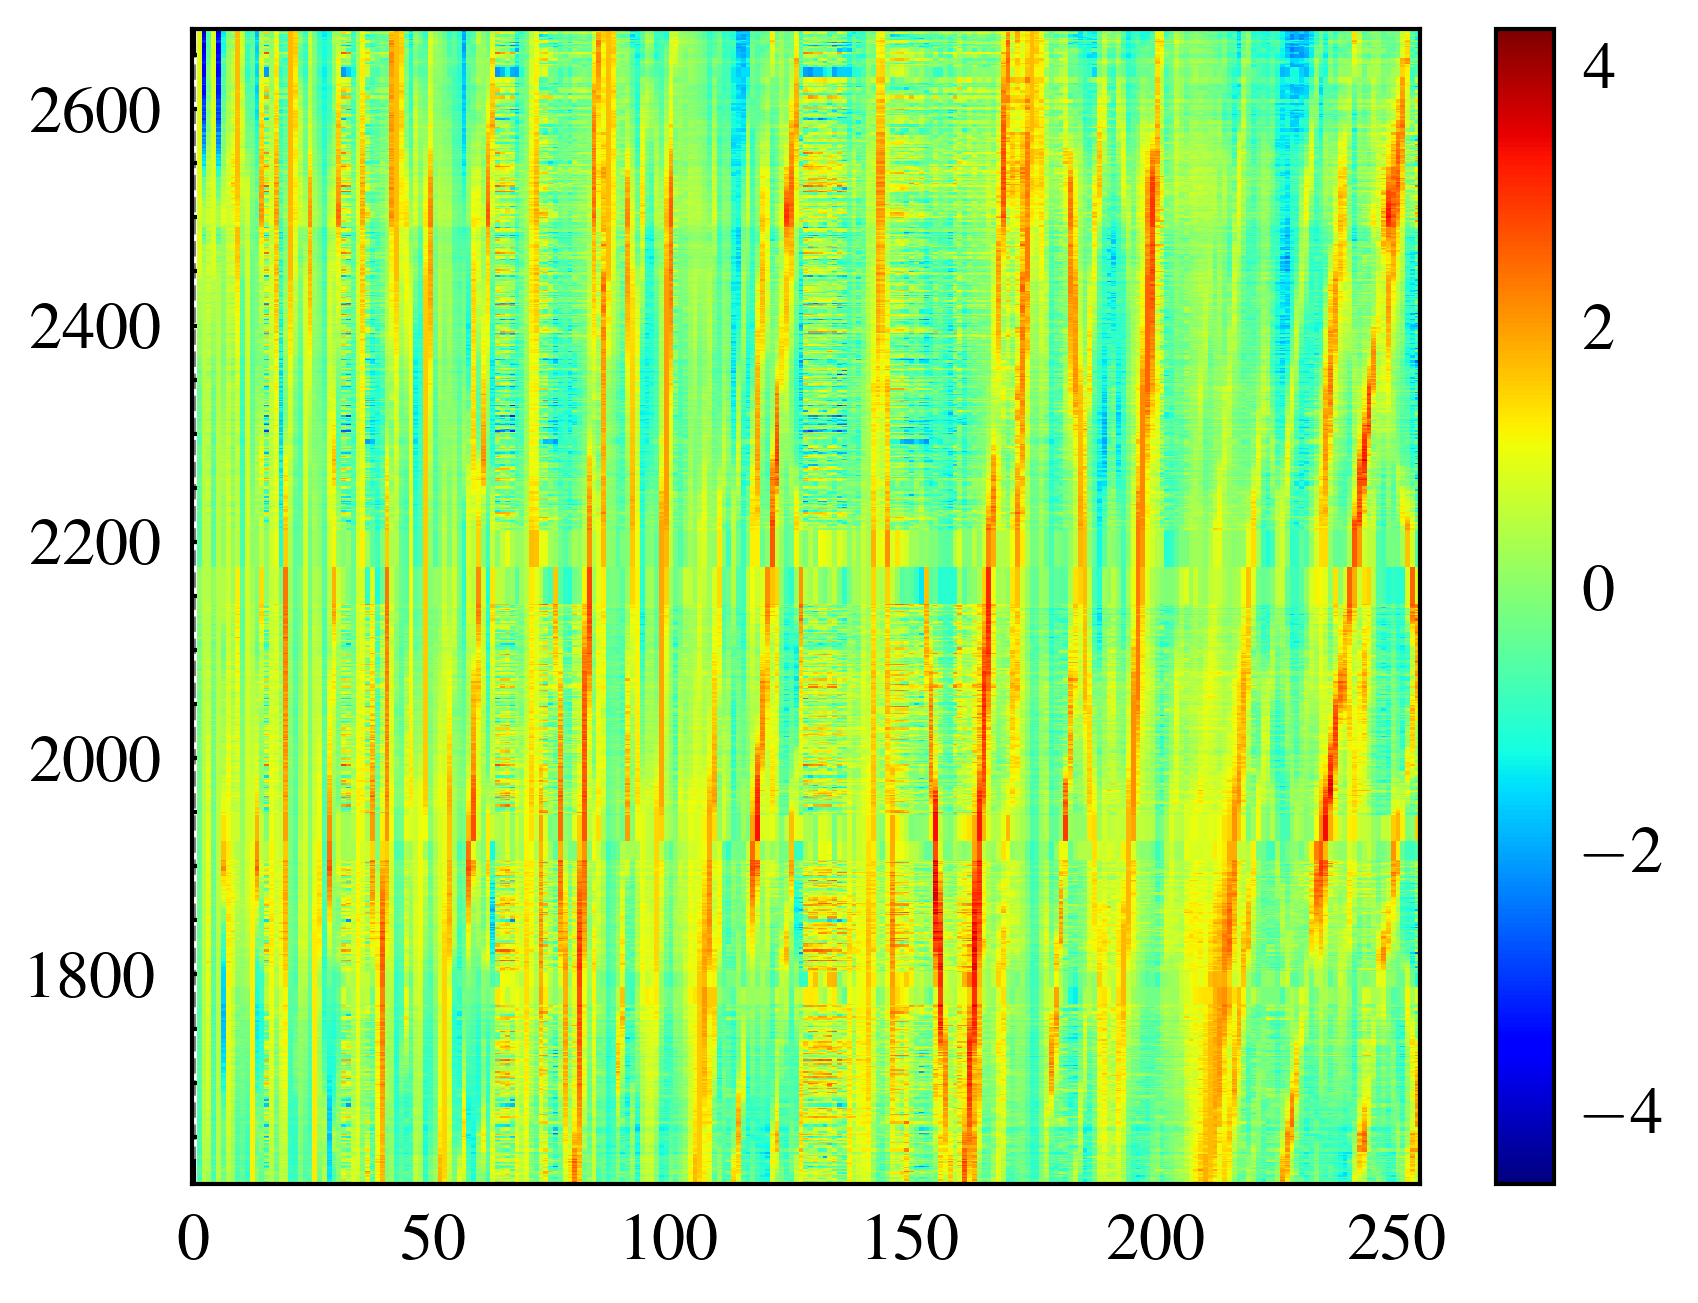

In [302]:
l = 6
cable = 1

#ind = index_per_level[l]
ind = np.arange(xn_per_cable[cable].shape[1])

x = xn_per_cable[cable][:,ind]
x_z = (x - mu[ind]) / std[ind].reshape(1,-1)

t = t_per_cable[cable]

plt.pcolormesh(ind, t, x_z, cmap="jet")
plt.colorbar()

In [ ]:
from lib.wpt_utils import (
    normalize_by_level,
    plot_wpt,
    get_wpt_from_lms,
    combine_wpts,
    get_wpt_arrays,
    build_index_per_level,
    build_index_per_level,
    limit_wpt_level
)

## Plots

In [ ]:
cobined_c1 = [combine_wpts([d.sample_c1.y, d.sample_c1.z]) for d in data]
cobined_c2 = [combine_wpts([d.sample_c2.y, d.sample_c2.z]) for d in data]
cobined_c3 = [combine_wpts([d.sample_c3.y, d.sample_c3.z]) for d in data]
cobined_c4 = [combine_wpts([d.sample_c4.y, d.sample_c4.z]) for d in data]

In [ ]:
normalized_c1 = [normalize_by_level(wpt) for wpt in cobined_c1]
normalized_c2 = [normalize_by_level(wpt) for wpt in cobined_c2]
normalized_c3 = [normalize_by_level(wpt) for wpt in cobined_c3]
normalized_c4 = [normalize_by_level(wpt) for wpt in cobined_c4]

In [ ]:
tensions_c1 = [d.sample_c1.tension for d in data]
tensions_c2 = [d.sample_c2.tension for d in data]
tensions_c3 = [d.sample_c3.tension for d in data]
tensions_c4 = [d.sample_c4.tension for d in data]

In [ ]:
def plot_wpt(
    wpt_list: List[WaveletPacket],
    y_values: List[float],
    mode: str = "energy",  # "energy" or "entropy"
    level: Optional[int] = None,
    db_scale: bool = False,
    cable: int = 1, # for plotting
    seq : int = 1, # for plotting
) -> None:
    """
    Plots a 2D colormap of wavelet packet energy or entropy for a list of WaveletPacket objects.

    Parameters:
    -----------
    wpt_list : List[WaveletPacket]
        A list of WaveletPacket objects to be plotted.
    y_values : List[float]
        A list of y-axis values corresponding to each WaveletPacket object.
    mode : str, optional
        The mode to plot, either "energy" or "entropy". Default is "energy".
    level : int, optional
        The specific decomposition level to plot. If None, plots all levels. Default is None.
    db_scale : bool, optional
        If True, converts the values to decibel (dB) scale. Default is False.
    """
    if not wpt_list:
        print("No WaveletPacket objects to plot.")
        return

    if len(y_values) != len(wpt_list):
        raise ValueError("len(y_values) must match len(wpt_list).")

    # 1) Determine the subband dimension from the first packet
    wpt0 = wpt_list[0]
    if mode.lower() == "energy":
        data0 = np.ravel(wpt0.energy_map)
    else:
        data0 = np.ravel(wpt0.entropy_map)

    # 2) Create a 2D array: rows = wavelet packets, columns = subband indices
    index_per_level = build_index_per_level(max_level=wpt0.max_level + 1)
    if not level:
        ind = np.hstack([list(i) for i in index_per_level.values()])
    else:
        ind = np.array(index_per_level[level])

    num_subbands = len(ind)
    data_2d = np.zeros((len(wpt_list), num_subbands), dtype=float)
    for i, wpt_obj in enumerate(wpt_list):
        if mode.lower() == "energy":
            arr = np.ravel(wpt_obj.energy_map)[ind]
        else:
            arr = np.ravel(wpt_obj.entropy_map)[ind]

        if len(arr) != num_subbands:
            raise ValueError(
                "All WaveletPacket objects must have the same subband dimension."
            )

        # Convert to dB if requested
        if db_scale:
            arr = np.maximum(arr, 1e-20)
            arr = 20.0 * np.log10(arr)

        data_2d[i, :] = arr

    # 3) Subband index array
    subband_indices = np.arange(num_subbands)

    # 4) Plot the pcolormesh
    fig, ax = plt.subplots(figsize=(3, 2))
    y_array = np.array(y_values)
    y_index = np.argsort(y_array)
    mesh = ax.pcolormesh(
        subband_indices,  # X-axis: subband index
        y_array[y_index],  # Y-axis: user-provided values
        data_2d[y_index,:],
        shading="auto",
        cmap="Blues"
    )
    cbar = plt.colorbar(mesh, ax=ax)
    # cbar.set_label(("dB " if db_scale else "") + mode)
    cbar.set_label("$E_i^{("+ str(level) +")}$")
    #ax.set_title(f"Wavelet Packet {mode.capitalize()} Map (Y from input list)")
    ax.set_xlabel("Sub-band index $i$")
    ax.set_ylabel("Tension (N)")
    step = num_subbands//8
    step = 1 if step == 0 else step
    ax.set_xticks(np.arange(0, num_subbands, step))

    ax2 = ax.twiny()
    step_f = 32 if level ==2 else 128 // 8
    ax2.set_xticks(np.arange(0, 128+1, step_f))
    ax2.set_xlabel("Frequency (Hz)")
    ax2.grid(False)
    plt.tight_layout()
    plt.savefig(f"figures_wpt_results/wpt_cable{cable}_seq{seq}_level{level}.png", dpi=300)
    plt.show()

NameError: name 'List' is not defined

In [ ]:
for level in [3,4,5,6,7,8]:
    plot_wpt(
        normalized_c1, tensions_c1, mode="energy", level=level, cable=1, seq=1
    )

# CWT

In [ ]:
def plot_stft(
    signal: np.ndarray,
    dt: float,
    f_min: float,
    f_max: float,
    nperseg: int = 256,
    noverlap: int = 128,
    window: str = "hann",
) -> None:
    """
    Compute and plot the Short-Time Fourier Transform (STFT) of an input signal
    over a given frequency range [f_min, f_max].

    Args:
        signal (np.ndarray): 1D array representing the input signal.
        dt (float): Time spacing between samples (seconds per sample).
        f_min (float): Minimum frequency of interest in Hz.
        f_max (float): Maximum frequency of interest in Hz.
        nperseg (int): Length of each segment for STFT (default=256).
        noverlap (int): Number of points to overlap between segments (default=128).
        window (str): Window function name (default="hann").

    Returns:
        None
    """
    # Sampling frequency
    fs = 1.0 / dt

    # Compute STFT
    freqs, times, Zxx = stft(
        signal, fs=fs, window=window, nperseg=nperseg, noverlap=noverlap
    )

    # Filter frequencies based on f_min and f_max
    freq_mask = (freqs >= f_min) & (freqs <= f_max)
    freqs = freqs[freq_mask]
    Zxx = Zxx[freq_mask, :]

    # Plot the magnitude of STFT coefficients
    plt.figure(figsize=(10, 6))
    plt.pcolormesh(
        times,
        freqs,
        np.abs(Zxx),
        shading="auto",
        cmap="jet",
    )
    plt.colorbar(label="Magnitude")
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"STFT: {f_min} Hz to {f_max} Hz")
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_morlet_cwt(
    signal: np.ndarray,
    dt: float,
    f_min: float,
    f_max: float,
    x_min: float,
    x_max: float,
    num_scales: int = 50,
    normalized: bool = False,
) -> None:
    """
    Compute and plot the Morlet CWT of an input signal over a given frequency range [f_min, f_max].

    Args:
        signal (np.ndarray): 1D array representing the input signal.
        dt (float): Time spacing between samples (seconds per sample).
        f_min (float): Minimum frequency of interest in Hz.
        f_max (float): Maximum frequency of interest in Hz.
        num_scales (int): Number of frequency points (and thus scales) to use between f_max and f_min.

    Returns:
        None
    """
    # Morlet wavelet parameters
    # wavelet = "morl"
    wavelet = "mexh"
    center_freq = pywt.central_frequency(wavelet)  # ~0.8129 for "morl"

    # Define frequencies in descending order (from f_max down to f_min)
    freqs = np.linspace(f_max, f_min, num_scales)

    # Convert frequencies to scales
    scales = center_freq / (freqs * dt)

    # Compute CWT using pywt
    # cwt_matrix has shape (num_scales, len(signal)).
    # Each row corresponds to a scale in ascending order.
    cwt_matrix, _ = pywt.cwt(signal, scales, wavelet)

    # Time axis for plotting
    t_min, t_max = 0.0, len(signal) * dt

    # Plot the magnitude of the CWT coefficients
    plt.figure(figsize=(10, 6))

    # We set origin='upper' so that the first row (row=0) appears at the top (f_max),
    # and the last row (row=num_scales-1) appears at the bottom (f_min).
    # extent = [left, right, bottom, top]
    # Here, left=0 (t_min), right=t_max, bottom=f_min, top=f_max.
    if normalized:
        normalized_cwt_matrix = np.abs(cwt_matrix) / np.abs(cwt_matrix).max(axis=0)
    else:
        normalized_cwt_matrix = np.abs(cwt_matrix)
    
    plt.pcolormesh(np.arange(t_min, t_max, dt), freqs, normalized_cwt_matrix, cmap="jet")

    plt.colorbar(label="Magnitude")
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"Morlet CWT: {f_min} Hz to {f_max} Hz")
    plt.xlim([x_min, x_max])
    plt.show()

    return freqs, normalized_cwt_matrix

## Simulated signals

In [ ]:
f0 = 10
f1 = 30
a = 1
dt = 1 / 256
t_max = 50
t = np.arange(0, t_max, dt)
n = len(t)
f = np.linspace(f0, f1, n)

sig_0 = a * np.sin(2 * np.pi * f0 * t)
sig_1 = a * np.sin(2 * np.pi * f1 * t)

sig_2 = np.zeros_like(sig_0)
sig_2[0:n//2] = sig_0[0:n//2]
sig_2[n//2:] = sig_1[n//2:]

sig_3 = a * np.sin(2*np.pi*f*t)

In [ ]:
freqs, matrix = plot_morlet_cwt(
    signal=sig_0,
    dt=dt,
    f_min=5,
    f_max=40,
    num_scales=1000,
    x_min=0,
    x_max=t_max,
    normalized=False,
)

In [ ]:
freqs, matrix = plot_morlet_cwt(
    signal=sig_1,
    dt=dt,
    f_min=5,
    f_max=40,
    num_scales=1000,
    x_min=0,
    x_max=t_max,
    normalized=False,
)

In [ ]:
freqs, matrix = plot_morlet_cwt(
    signal=sig_2,
    dt=dt,
    f_min=5,
    f_max=40,
    num_scales=1000,
    x_min=0,
    x_max=t_max,
    normalized=False,
)

In [ ]:
freqs, matrix = plot_morlet_cwt(
    signal=sig_3,
    dt=dt,
    f_min=5,
    f_max=40,
    num_scales=1000,
    x_min=0,
    x_max=t_max,
    normalized=False,
)

## Real data

In [ ]:
plot_stft(sample.c1_z, sample.dt, 10, 25, 2048, 512)

In [ ]:
freqs, matrix = plot_morlet_cwt(
    signal=sample.c1_z,
    dt=sample.dt,
    f_min=5,
    f_max=25,
    num_scales=1350,
    x_min=0,
    x_max=64,
    normalized=False,
)

# Wavelet Packet

In [ ]:
def wavelet_packet_decomposition(
    signal: np.ndarray,
    wavelet: str = "db1",
    maxlevel: int = None,
    mode: str = "symmetric",
) -> dict:
    """
    Perform wavelet packet decomposition on a 1D signal and return the coefficients for each node.

    Args:
        signal (np.ndarray): 1D array representing the input signal.
        wavelet (str): Name of the wavelet to use (default="db1").
        maxlevel (int): Maximum number of decomposition levels (default=None, which lets pywt decide).
        mode (str): Signal extension mode (default="symmetric").

    Returns:
        dict: A dictionary where each key is a node path (e.g., 'aaa', 'aab', ...)
              and each value is the wavelet packet coefficients for that node.
    """
    # Create the wavelet packet object
    wp = pywt.WaveletPacket(data=signal, wavelet=wavelet, mode=mode, maxlevel=maxlevel)

    # Get the paths of all leaf nodes at the deepest level
    leaf_nodes = wp.get_leaf_nodes(True)
    leaf_paths = [node.path for node in leaf_nodes]

    # Collect coefficients in a dictionary
    coeffs_dict = {path: wp[path].data for path in leaf_paths}

    return coeffs_dict

In [ ]:
def plot_psd(
    signal,
    ax,
    fs: float = 1.0,
    nperseg: int = 256,
    noverlap: int = None,
    window: str = "hann",
) -> None:
    """
    Compute and plot the Power Spectral Density (PSD) of a 1D signal
    using Welch's method.

    Args:
        signal (np.ndarray): 1D array representing the input signal.
        fs (float): Sampling frequency (default=1.0).
        nperseg (int): Length of each segment for the Welch method (default=256).
        noverlap (int): Number of points to overlap between segments (default=None).
        window (str): Window function name (default="hann").

    Returns:
        None
    """
    freqs, psd = welch(signal, fs=fs, window=window, nperseg=nperseg, noverlap=noverlap)

    # plt.plot(freqs, psd)
    ax.semilogy(freqs, psd)
    ax.set_xlabel("Frequency [Hz]")
    # plt.show()

# Coefficient comparison

In [ ]:
from lib.wpt_utils import get_wpt_from_lms

In [ ]:
path = meta_1.iloc[100]["path"]
raw = LMSFile.from_txt(path)

In [ ]:
wp_db4 = pywt.WaveletPacket(data=raw.c1_y, wavelet="db4", maxlevel=8, mode="symmetric")
wp_db35 = pywt.WaveletPacket(data=raw.c1_y, wavelet="db35", maxlevel=8, mode="symmetric")